In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dataset.dataset import load_data
from dataset.utils import *

def get_dataset(return_orig=False, return_path=False, shuffle=True):
	n_concepts = 5
	val_loader = load_data("../dataset/celebA/splits/cbm/train.pkl", 16, dataset_root="../dataset/celebA/", return_orig=return_orig, return_path=return_path, shuffle=shuffle, dataset_name="celebA", x_resize=178, y_resize=218)
	concept_index_to_string = IndexToString("../dataset/celebA/splits/cbm/concepts.txt")

	return n_concepts, val_loader, concept_index_to_string

In [3]:
device = get_device(cpu=True)

N_CONCEPT, test_loader, concept_index_to_string = get_dataset(return_orig=True, return_path=False, shuffle=True)

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./../saves/celebA_XtoC_converted.pth"))
XtoC.to(device)
XtoC.eval()

print("model loaded")

Device: cpu NVIDIA GeForce RTX 3050 Ti Laptop GPU
model loaded


In [4]:
XtoC = convert(XtoC).to(device)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

True image size (channels, width, height): torch.Size([3, 218, 178])
True  image concepts: tensor([0., 1., 1., 0., 1.])


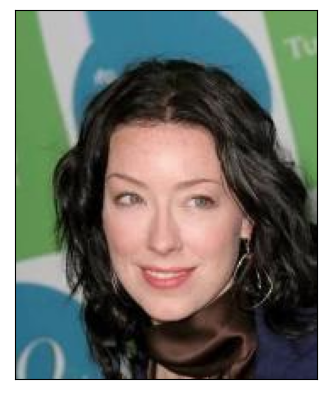

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


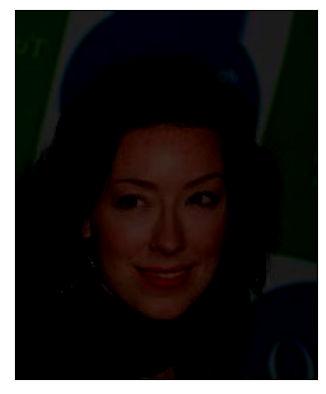

In [44]:
imageId = 7

images, labels, concepts, extra = next(iter(test_loader))
orig_imgs = extra["orig_img"]
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(orig_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [45]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

print(prediction)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

tensor([[-1.7071,  3.8099,  3.5271,  0.3003,  2.3069]],
       grad_fn=<AddmmBackward0>)
Predicted concepts: tensor([[0.1535, 0.9783, 0.9714, 0.5745, 0.9094]], grad_fn=<SigmoidBackward0>)
id: 1, concept name: High_Cheekbones, sig value: 0.9783303141593933
id: 2, concept name: No_Beard, sig value: 0.9714497923851013
id: 3, concept name: Oval_Face, sig value: 0.5745151042938232
id: 4, concept name: Wavy_Hair, sig value: 0.9094481468200684


In [46]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 15:
        XtoC_model_1.append(m)
    elif idx < 29:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device).eval()
XtoC_model_2.to(device).eval()
XtoC_model_3.to(device).eval()

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

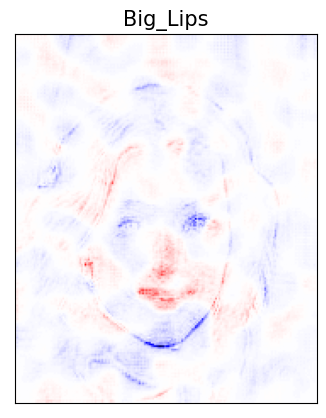

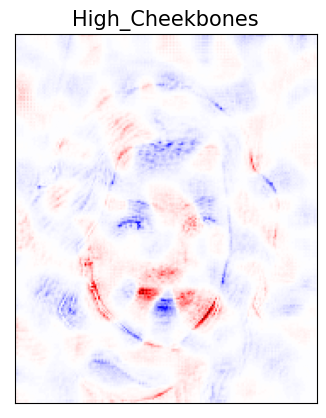

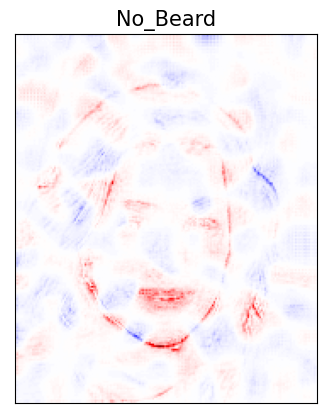

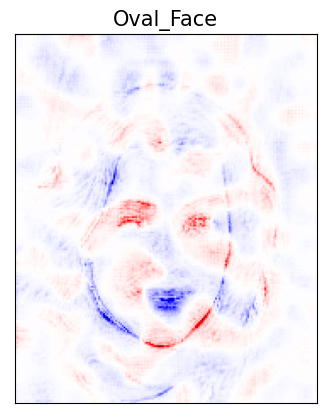

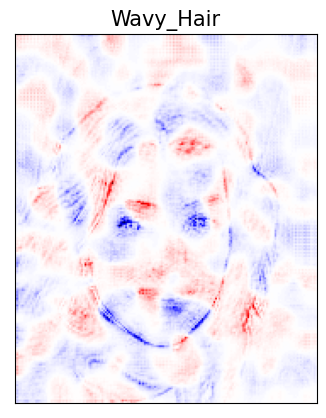

In [47]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 
